# 05 Modelling

This notebook corresponds to the **Machine Learning Modelling** stage.

Goals:
- Predict band of utilisation of bycicles per station in the next 30 minutes


In [1]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix


PROJECT_ROOT = Path('..').resolve()
FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features.parquet'
if not FEATURES_PATH.exists():
    FEATURES_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dublin_bikes_features.csv.gz'

if FEATURES_PATH.suffix == '.parquet':
    df = pd.read_parquet(FEATURES_PATH).copy()
else:
    df = pd.read_csv(FEATURES_PATH).copy()

df = df.sort_values(['station_id', 'last_reported'])
print(df.shape)
df.head()

(13513883, 13)


,station_id,last_reported,hour_slot,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,empty_risk,full_risk,center_index,area_type_str
0,1,2022-04-27 13:00:02,2022-04-27 13:00:00,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail
1,1,2022-04-27 13:30:02,2022-04-27 13:30:00,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail
2,1,2022-04-27 14:00:02,2022-04-27 14:00:00,2,True,0.0,0.0,0.0,0.870968,True,False,1,retail
3,1,2022-04-27 14:30:02,2022-04-27 14:30:00,2,True,0.0,0.0,0.0,0.000000,True,False,1,retail
4,1,2022-04-27 15:00:02,2022-04-27 15:00:00,2,True,0.0,0.0,0.0,0.000000,True,False,1,retail


In [2]:
# For each station, get the *next* utilisation value *only when* the hour_slot changes (i.e., at transitions to a new slot)
# The "future" is only valid at the moment the hour changes to a new slot

# Find the indices where the hour_slot changes for each station
df['utilisation_tplus'] = (
    df.groupby('station_id').apply(
        lambda g: g['utilisation'].shift(-1).where(g['hour_slot'].shift(-1) != g['hour_slot'])
    ).reset_index(level=0, drop=True)
)

# Only keep the rows where the hour_slot changes in the next row (i.e. where we have a valid tplus)
df = df.dropna(subset=['utilisation_tplus']).copy()

# Define bands for 30‑min ahead utilisation 
bins = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
band_labels = ["0–20%", "20–40%", "40–60%", "60–80%", "80–100%"]

df['util_band_30min'] = pd.cut(
    df['utilisation_tplus'].clip(0.0, 1.0),
    bins=bins,
    labels=band_labels,
    include_lowest=True
)

/var/folders/xv/ph0fds913cj0jv4p3py80zj00000gn/T/ipykernel_5135/1859848568.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby('station_id').apply(


In [3]:
# Features & Time based split

# Convert hour_slot to datetime, then extract the hour and minute in integer form (e.g., 08:30 → 830) and assign to new variable hour_slot_int
df['hour_slot_int'] = df['hour_slot'].dt.hour * 100 + df['hour_slot'].dt.minute


feature_cols = [
    'hour_slot_int', 'days_of_week', 'is_weekday', 
    'roll_std_30min','utilisation',
    'center_index', 'area_type_str'
]

X = df[feature_cols]
y = df['util_band_30min'].copy()          

# One‑hot encode area type
X = pd.get_dummies(X, columns=['area_type_str'], drop_first=True)

# Time‑based split: last 120 days as test
cutoff = df['hour_slot'].max() - pd.Timedelta(days=120)
train_mask = df['hour_slot'] < cutoff

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)
y_train.value_counts(normalize=True).sort_index()

Train shape: (7031007, 8) Test shape: (969016, 8)


util_band_30min
0–20%      0.349588
20–40%     0.219741
40–60%     0.175175
60–80%     0.122785
80–100%    0.132711
Name: proportion, dtype: float64

In [4]:
# Normalization & Training the Multinomial Logistic Model




scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(
    max_iter=300,
    class_weight='balanced',
    solver='lbfgs',
)

log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)

print(classification_report(y_test, y_pred))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred, labels=band_labels))

              precision    recall  f1-score   support

       0–20%       0.98      0.95      0.97    355714
      20–40%       0.90      0.93      0.91    203642
      40–60%       0.92      0.91      0.91    163264
      60–80%       0.90      0.92      0.91    117950
     80–100%       0.96      0.97      0.96    128446

    accuracy                           0.94    969016
   macro avg       0.93      0.94      0.93    969016
weighted avg       0.94      0.94      0.94    969016

Confusion matrix:
 [[339262  16216    157     44     35]
 [  5917 188394   9122    152     57]
 [   188   5645 148907   8286    238]
 [    28     89   4425 108434   4974]
 [    20     16     37   3806 124567]]


In [5]:
# To compare true bands to predicted bands
test_results = df.loc[~train_mask, ['station_id', 'hour_slot']].copy()
test_results['true_band_30min'] = y_test.values
test_results['pred_band_30min'] = y_pred

proba_cols = [f"p_{b}" for b in band_labels]
test_results[proba_cols] = y_proba

test_results.head()

,station_id,hour_slot,true_band_30min,pred_band_30min,p_0–20%,p_20–40%,p_40–60%,p_60–80%,p_80–100%
96498,1,2025-05-03 23:30:00,40–60%,40–60%,0.000006,0.068086,0.807303,0.124550,0.000055
96501,1,2025-05-04 00:00:00,40–60%,40–60%,0.000007,0.075864,0.816798,0.107291,0.000039
96504,1,2025-05-04 00:30:00,40–60%,40–60%,0.000007,0.075775,0.816709,0.107468,0.000040
96506,1,2025-05-04 00:00:00,40–60%,40–60%,0.000007,0.075864,0.816798,0.107291,0.000039
96508,1,2025-05-04 01:00:00,40–60%,40–60%,0.000007,0.075570,0.816501,0.107882,0.000040


In [6]:
# Function to predict the Band of availability of the stations at a specific time

def predict_30min_all_stations(time):
    # 1. Convert input time to pandas datetime
    time = pd.to_datetime(time)

    # 2. Subset the data: Take all rows in df before or equal to the given 'time'
    sub = df[df['hour_slot'] <= time].copy()
    if sub.empty:
        raise ValueError("No data before this time.")

    # 3. Among those, keep only the latest measurement per station
    #    - Sort by 'station_id' and 'last_reported'
    #    - For each station_id, keep the last (most recent) row
    sub = (
        sub.sort_values(['station_id', 'hour_slot'])
           .groupby('station_id')
           .tail(1)
    )

    # 4. Prepare input features for the model:
    #    - Select only the columns used in training (feature_cols)
    #    - Convert categorical variables to dummies (matching model expectations)
    X_rows = sub[feature_cols].copy()
    X_rows = pd.get_dummies(X_rows, columns=['area_type_str'], drop_first=True)

    # 5. Ensure feature columns match those used in training:
    #    - For each column in the training set, add if missing (set to 0)
    #    - Rearrange columns to match the training set
    for col in X_train.columns:
        if col not in X_rows.columns:
            X_rows[col] = 0
    X_rows = X_rows[X_train.columns]

    # 6. Transform the data (normalization/scaling) as during training
    X_rows_scaled = scaler.transform(X_rows)

    # 7. Run the model to get predictions
    y_pred_rows = log_reg.predict(X_rows_scaled)            # predicted band class
    y_proba_rows = log_reg.predict_proba(X_rows_scaled)     # probability for each band

    # 8. Build the output DataFrame:
    #    - Copy station_id and last_reported columns
    #    - Add predicted band
    out = sub[['station_id', 'hour_slot']].copy()
    out['pred_band_30min'] = y_pred_rows

    #    - Add predicted probability for each band (probability columns)
    for i, band in enumerate(band_labels):
        out[f"p_{band}"] = y_proba_rows[:, i]

    # 9. Return results sorted by station, and reset index for a clean DataFrame
    return out.sort_values('station_id').reset_index(drop=True)

In [7]:
preds = predict_30min_all_stations("2024-08-15 08:30:00")
preds.head()

,station_id,hour_slot,pred_band_30min,p_0–20%,p_20–40%,p_40–60%,p_60–80%,p_80–100%
0,1,2024-08-15 08:30:00,20–40%,2.334398e-02,0.863215,1.132436e-01,1.972540e-04,5.231372e-10
1,2,2024-08-15 08:30:00,0–20%,9.944619e-01,0.005537,7.820059e-07,1.510621e-12,2.021154e-21
2,3,2024-08-15 08:30:00,0–20%,6.629826e-01,0.335415,1.602075e-03,9.918820e-08,6.840747e-15
3,4,2024-08-15 08:30:00,60–80%,6.895767e-09,0.002222,3.684839e-01,6.242807e-01,5.013237e-03
4,5,2024-08-15 08:30:00,0–20%,6.886001e-01,0.309863,1.536814e-03,1.014419e-07,8.592489e-15


In [8]:
df[df['hour_slot'] == "2024-08-15 09:00:00"]

,station_id,last_reported,hour_slot,days_of_week,is_weekday,roll_mean_30min,roll_std_30min,utilisation,dock_ratio,empty_risk,full_risk,center_index,area_type_str,utilisation_tplus,util_band_30min,hour_slot_int
52174,1,2024-08-15 09:10:00,2024-08-15 09:00:00,3,True,0.266129,0.013968,0.290323,0.709677,False,False,1,retail,0.258065,20–40%,900
52179,1,2024-08-15 09:55:00,2024-08-15 09:00:00,3,True,0.306452,0.036066,0.354839,0.645161,False,False,1,retail,0.322581,20–40%,900
174525,2,2024-08-15 09:10:00,2024-08-15 09:00:00,3,True,0.000000,0.000000,0.000000,1.000000,True,False,2,residential,0.000000,0–20%,900
174530,2,2024-08-15 09:50:00,2024-08-15 09:00:00,3,True,0.075000,0.025000,0.100000,0.900000,False,False,2,residential,0.050000,0–20%,900
290798,3,2024-08-15 09:10:00,2024-08-15 09:00:00,3,True,0.062500,0.021651,0.050000,0.950000,False,False,1,residential,0.000000,0–20%,900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13223389,115,2024-08-15 09:50:00,2024-08-15 09:00:00,3,True,0.508333,0.014434,0.500000,0.500000,False,False,2,residential,0.466667,40–60%,900
13344832,116,2024-08-15 09:05:00,2024-08-15 09:00:00,3,True,0.000000,0.000000,0.000000,1.000000,True,False,2,residential,0.000000,0–20%,900
13344837,116,2024-08-15 09:55:00,2024-08-15 09:00:00,3,True,0.000000,0.000000,0.000000,1.000000,True,False,2,residential,0.000000,0–20%,900
13455368,117,2024-08-15 09:10:00,2024-08-15 09:00:00,3,True,0.700000,0.000000,0.700000,0.300000,False,False,3,residential,0.700000,60–80%,900


# Random Forest Model

In [9]:
# Training the RF classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import numpy as np

# Use the same FEATURES and TARGET already defined in the notebook
rf_model = RandomForestClassifier(
    n_estimators=100,        # 100 trees — good starting point
    max_depth=15,            # prevents overfitting on 13M rows
    min_samples_leaf=50,     # smooths predictions
    n_jobs=-1,               # uses all CPU cores — important for speed
    random_state=42,
    class_weight='balanced'  # handles class imbalance (0-20% and 80-100% are rarer)
)

rf_model.fit(X_train, y_train)
print("Training complete.")


Training complete.


In [10]:
# Evaluation of the classifier
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=rf_model.classes_))
# The 0-20 and the 80-100 bands are the most important and they have the highest precision and recall and f1 score

Accuracy: 0.9523712714753936

Classification Report:
              precision    recall  f1-score   support

       0–20%       0.98      0.98      0.98    355714
      20–40%       0.93      0.93      0.93    203642
      40–60%       0.93      0.93      0.93    163264
      60–80%       0.92      0.92      0.92    117950
     80–100%       0.97      0.97      0.97    128446

    accuracy                           0.95    969016
   macro avg       0.95      0.95      0.95    969016
weighted avg       0.95      0.95      0.95    969016



In [11]:
import matplotlib as plt

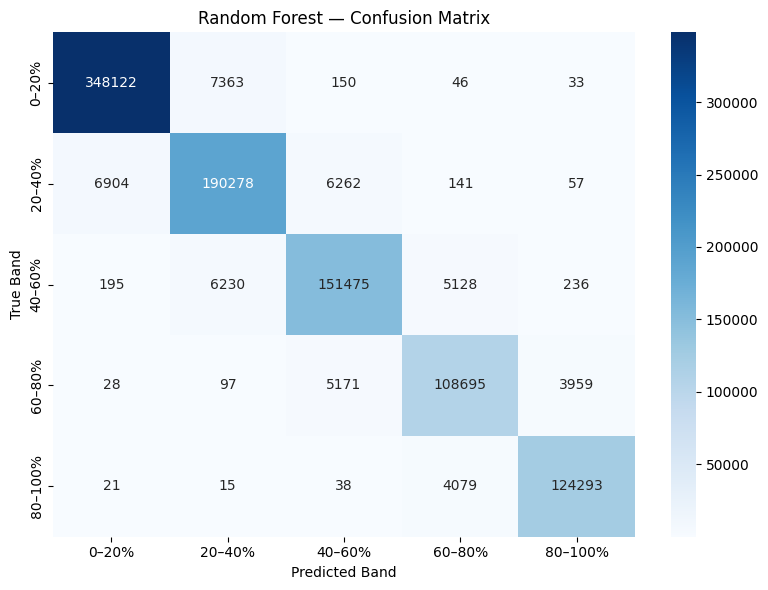

In [12]:
#Confusion matrix for the rf model
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred_rf, labels=rf_model.classes_)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=rf_model.classes_,
            yticklabels=rf_model.classes_)
plt.title('Random Forest — Confusion Matrix')
plt.ylabel('True Band')
plt.xlabel('Predicted Band')
plt.tight_layout()
plt.show()


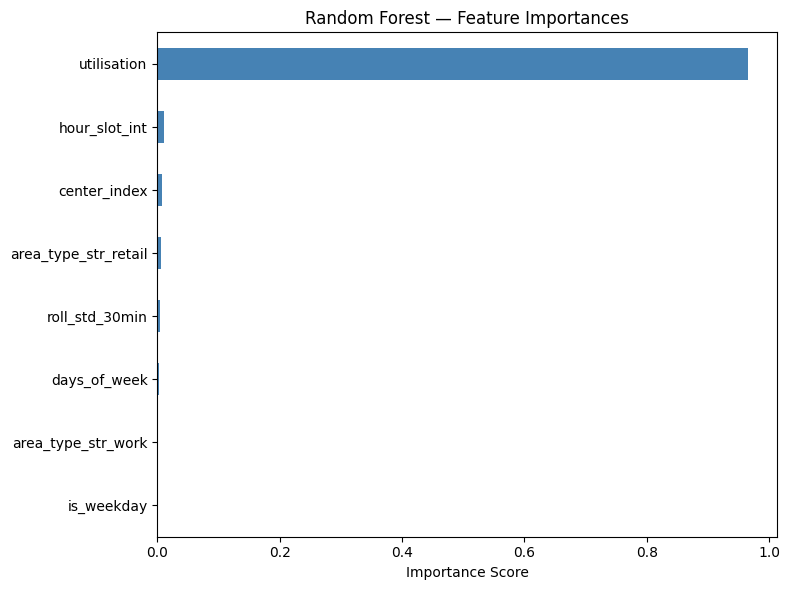

In [13]:
#showing which feature is the most important
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances.sort_values().plot(kind='barh', figsize=(8, 6), color='steelblue')
plt.title('Random Forest — Feature Importances')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()


So far i have performed random forest classifier on the same train/test split and the results are good especially on the 0-20 and 80-100 bins


# LSTM

In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models

2026-03-22 22:38:23.309419: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/sarroyomart/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [15]:
# Selecting features for the model and sorting them 
import numpy as np


SEQ_FEATURES = [
    'utilisation',
    'roll_mean_30min',
    'roll_std_30min',
    'hour_slot',
    'days_of_week',
    'center_index',
]

TARGET_COL = 'util_band_30min'  
# this means the model will look back at the past 6 time stamps and as each data point is 5 min apart so it becomes a 30 minute look back 

TIMESTEPS = 6 

In [16]:
band_to_idx = {b: i for i, b in enumerate(sorted(df[TARGET_COL].unique()))}
idx_to_band = {i: b for b, i in band_to_idx.items()}
df['target_idx'] = df[TARGET_COL].map(band_to_idx)
df_lstm = df.sort_values(['station_id', 'last_reported']).copy()
df_lstm['target_idx'] = df_lstm[TARGET_COL].map(band_to_idx)
#Converted string labels to integers for LSTM model

In [17]:
X_seq = []
y_seq = []

for station_id, group in df_lstm.groupby('station_id', sort=False):
    g = group.reset_index(drop=True)
    feat = g[SEQ_FEATURES].to_numpy()
    tgt  = g['target_idx'].to_numpy()

    # sliding window
    for i in range(len(g) - TIMESTEPS):
        X_seq.append(feat[i:i+TIMESTEPS])
        y_seq.append(tgt[i+TIMESTEPS])   

X_seq = np.array(X_seq, dtype=np.float32)
y_seq = np.array(y_seq, dtype=np.int64)

X_seq.shape, y_seq.shape


TypeError: float() argument must be a string or a number, not 'Timestamp'

In [ ]:
#Train test split is 80-20
from sklearn.model_selection import train_test_split

X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq, y_seq, test_size=0.2, shuffle=False   
)


In [ ]:


num_classes = len(band_to_idx)

model = models.Sequential([
    layers.Input(shape=(TIMESTEPS, len(SEQ_FEATURES))),
    layers.LSTM(64, return_sequences=False),
    layers.Dense(64, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

history = model.fit(
    X_train_seq, y_train_seq,
    validation_split=0.1,
    epochs=5,              # start small; increase if training is stable
    batch_size=512,
    verbose=1,
)


Epoch 1/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 136s 7ms/step - accuracy: 0.8486 - loss: 0.4095 - val_accuracy: 0.8917 - val_loss: 0.2978
Epoch 2/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 128s 7ms/step - accuracy: 0.8572 - loss: 0.3774 - val_accuracy: 0.8971 - val_loss: 0.2855
Epoch 3/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 129s 7ms/step - accuracy: 0.8588 - loss: 0.3717 - val_accuracy: 0.8973 - val_loss: 0.2800
Epoch 4/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 128s 7ms/step - accuracy: 0.8595 - loss: 0.3687 - val_accuracy: 0.8980 - val_loss: 0.2807
Epoch 5/5
19003/19003 ━━━━━━━━━━━━━━━━━━━━ 136s 7ms/step - accuracy: 0.8600 - loss: 0.3668 - val_accuracy: 0.8971 - val_loss: 0.2789


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np

y_proba_lstm = model.predict(X_test_seq)
y_pred_lstm_idx = np.argmax(y_proba_lstm, axis=1)

# Map back to band labels if you want
y_test_bands = np.array([idx_to_band[i] for i in y_test_seq])
y_pred_bands = np.array([idx_to_band[i] for i in y_pred_lstm_idx])

print("LSTM Accuracy:", accuracy_score(y_test_seq, y_pred_lstm_idx))
print("\nLSTM Classification report:")
print(classification_report(y_test_seq, y_pred_lstm_idx, target_names=[idx_to_band[i] for i in range(num_classes)]))


84457/84457 ━━━━━━━━━━━━━━━━━━━━ 86s 1ms/step
LSTM Accuracy: 0.9086910608092308

LSTM Classification report:
              precision    recall  f1-score   support

       0–20%       0.95      0.96      0.96   1085744
      20–40%       0.87      0.88      0.87    635785
      40–60%       0.87      0.85      0.86    461840
      60–80%       0.87      0.82      0.84    250013
     80–100%       0.94      0.95      0.94    269234

    accuracy                           0.91   2702616
   macro avg       0.90      0.89      0.90   2702616
weighted avg       0.91      0.91      0.91   2702616

